# Matplotlib Basics: A Revision Notebook

Matplotlib is the Python library for drawing **charts**. The course labs use it to plot data, cost curves and model predictions.

**How to use this notebook**

- Read each text cell, then run the code cell under it (**Shift + Enter**).
- Each code cell draws one chart. Look at the chart, then reread the code and match each line to what you see.
- Change something (a color, a size, a number) and run again to see what it does.
- Run the cells **from top to bottom**.

**Contents**

1. Import
2. Figure and axes: the two things you always make
3. Line plot: `plot`
4. Titles and axis labels
5. Line style: color, line type, markers
6. Scatter plot: `scatter`
7. Hollow circles: `facecolors` and `edgecolors`
8. Legend
9. Axis limits
10. Math in labels: `$x_0$`
11. Several charts side by side: `subplots(1, 2)`
12. Extra lines: `axhline` and `axvline`
13. Other common charts: bar chart and histogram
14. Grid lines and saving to a file
15. Course examples
16. Cheat sheet

## 1. Import

`plt` is the usual short name for `matplotlib.pyplot`. We also import NumPy (`np`) to make data.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

## 2. Figure and axes: the two things you always make

```
┌─────────────── fig (the whole picture) ───────────────┐
│                                                       │
│   ┌──────── ax (one chart) ────────┐                  │
│   │  title                          │                 │
│   │  y-label |    data drawn here   │                 │
│   │          |_____________________ │                 │
│   │                x-label          │                 │
│   └─────────────────────────────────┘                 │
└───────────────────────────────────────────────────────┘
```

- **`fig`** is the whole picture, like a sheet of paper.
- **`ax`** is one chart on that paper. You draw on `ax`.

`plt.subplots()` makes both at once. `plt.show()` displays the result.

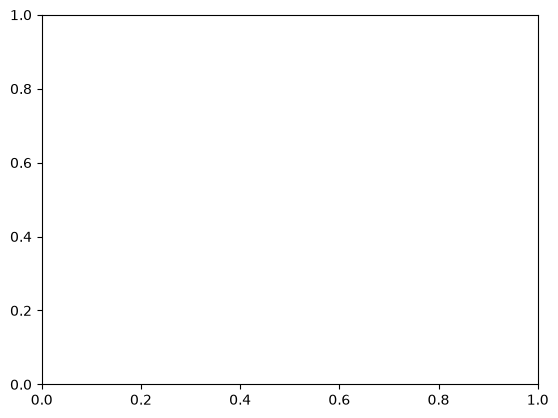

In [2]:
fig, ax = plt.subplots()   # one empty chart
plt.show()

`figsize=(width, height)` sets the size in inches:

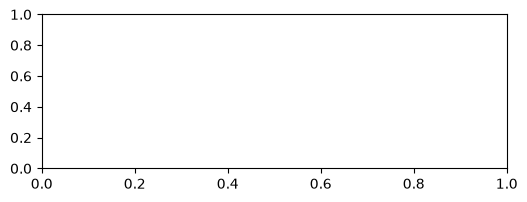

In [3]:
fig, ax = plt.subplots(figsize=(6, 2))   # wide and short
plt.show()

## 3. Line plot: `plot`

`ax.plot(x, y)` puts a point at each (x, y) pair and **joins them with a line**.

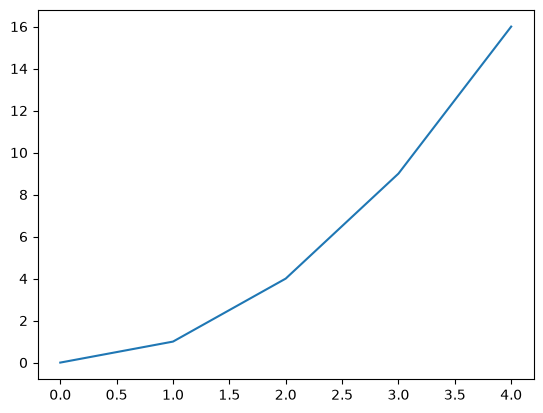

In [4]:
x = np.array([0, 1, 2, 3, 4])
y = np.array([0, 1, 4, 9, 16])

fig, ax = plt.subplots()
ax.plot(x, y)    # points (0,0), (1,1), (2,4), (3,9), (4,16) joined by a line
plt.show()

### Giving only one list

With one list, matplotlib uses it as **y** and fills in **x** as 0, 1, 2, 3, ... for you.

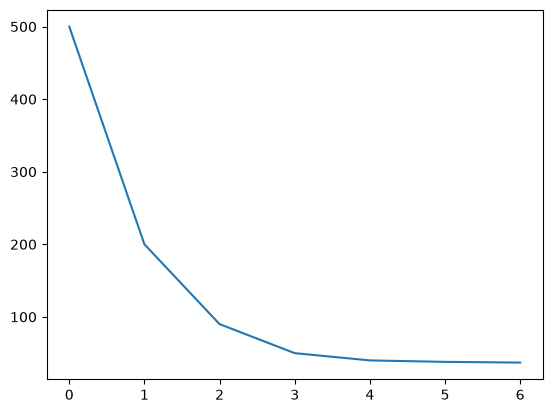

In [5]:
cost = [500, 200, 90, 50, 40, 38, 37]

fig, ax = plt.subplots()
ax.plot(cost)    # x is automatically 0, 1, 2, ..., 6
plt.show()

**Course example:** `ax.plot(J_hist)` plots the cost at each iteration of gradient descent.

## 4. Titles and axis labels

| Code | Puts text... |
|---|---|
| `ax.set_title("...")` | on top |
| `ax.set_xlabel("...")` | under the x-axis (bottom) |
| `ax.set_ylabel("...")` | beside the y-axis (left) |

`fontsize=12` makes the text bigger or smaller.

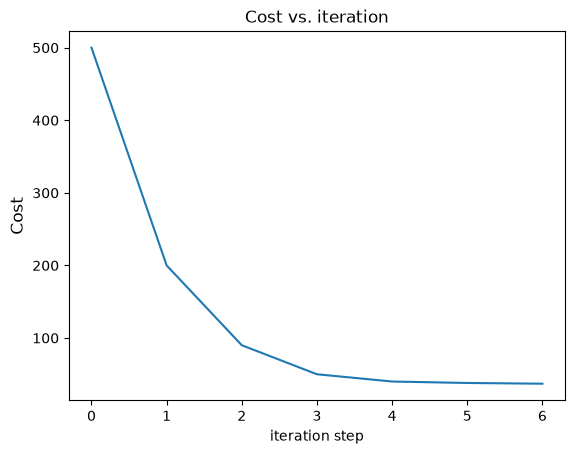

In [6]:
cost = [500, 200, 90, 50, 40, 38, 37]

fig, ax = plt.subplots()
ax.plot(cost)
ax.set_title("Cost vs. iteration")
ax.set_xlabel("iteration step")
ax.set_ylabel("Cost", fontsize=12)
plt.show()

## 5. Line style: color, line type, markers

| Setting | Meaning | Examples |
|---|---|---|
| `c=` (or `color=`) | color | `'b'` blue, `'r'` red, `'g'` green, `'k'` black, `'orange'`, `'#0096ff'` |
| `linestyle=` | line type | `'-'` solid, `'--'` dashed, `':'` dotted |
| `lw=` (or `linewidth=`) | line thickness | `1`, `3` |
| `marker=` | a symbol at each point | `'o'` circle, `'x'` cross, `'s'` square |

You can draw several lines on the same `ax`. Just call `plot` again.

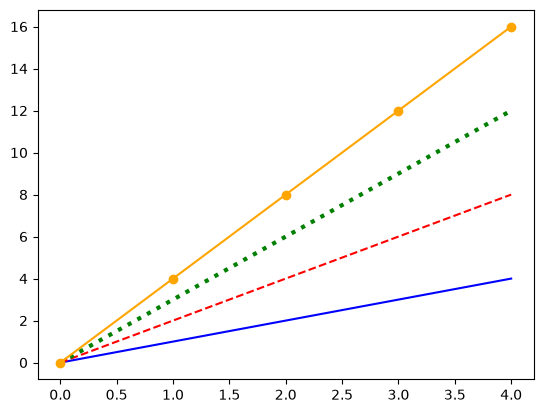

In [7]:
x = np.arange(5)

fig, ax = plt.subplots()
ax.plot(x, x,      c='b')                             # blue solid line
ax.plot(x, x * 2,  c='r', linestyle='--')             # red dashed line
ax.plot(x, x * 3,  c='g', linestyle=':', lw=3)        # thick green dotted line
ax.plot(x, x * 4,  c='orange', marker='o')            # orange line with circle markers
plt.show()

## 6. Scatter plot: `scatter`

`ax.scatter(x, y)` draws **separate dots** and doesn't join them. Use it for data points.

| Setting | Meaning |
|---|---|
| `marker=` | shape: `'o'` circle, `'x'` cross, `'s'` square, `'^'` triangle |
| `s=` | **size** of each mark (bigger number = bigger mark) |
| `c=` | color |

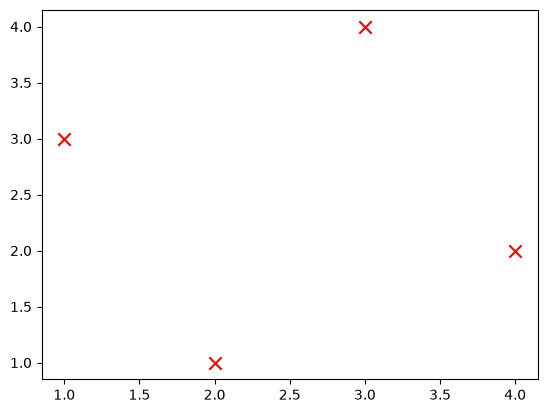

In [8]:
x = np.array([1, 2, 3, 4])
y = np.array([3, 1, 4, 2])

fig, ax = plt.subplots()
ax.scatter(x, y, marker='x', s=80, c='red')
plt.show()

### What `s` does

Each circle below has a different `s`:

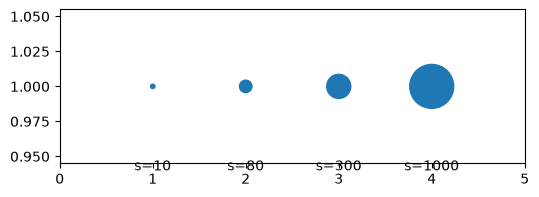

In [9]:
sizes = [10, 80, 300, 1000]

fig, ax = plt.subplots(figsize=(6, 2))
ax.scatter([1, 2, 3, 4], [1, 1, 1, 1], marker='o', s=sizes)
for x, size in zip([1, 2, 3, 4], sizes):
    ax.text(x, 0.94, f"s={size}", ha='center')   # write the size under each circle
ax.set_xlim(0, 5)
plt.show()

### `plot` vs `scatter`

- **`plot`**: points joined by a line. Use it for things that change smoothly, like cost over time or a model's prediction line.
- **`scatter`**: separate dots. Use it for data points, like training examples.

Very often you use both: `scatter` for the data and `plot` for the model's line.

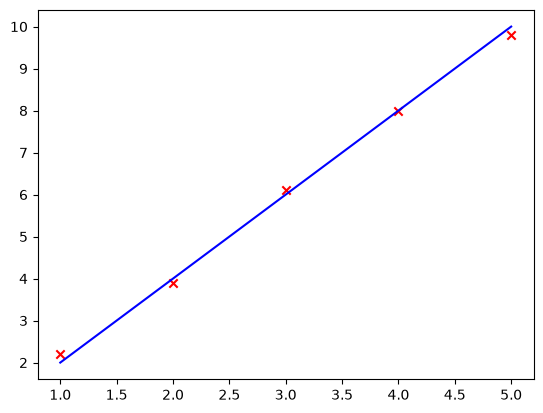

In [10]:
x = np.array([1, 2, 3, 4, 5])
y = np.array([2.2, 3.9, 6.1, 8.0, 9.8])   # data
f = 2 * x                                 # a model's predictions

fig, ax = plt.subplots()
ax.scatter(x, y, marker='x', c='r')   # data: red crosses
ax.plot(x, f, c='b')                  # model: blue line
plt.show()

## 7. Hollow circles: `facecolors` and `edgecolors`

A circle mark has two parts:

```
   edge (outline)  →  ( )  ←  face (the inside)
```

| Setting | Meaning |
|---|---|
| `facecolors=` | color of the **inside**. `'none'` = empty |
| `edgecolors=` | color of the **outline** |
| `lw=` | how thick the outline is |

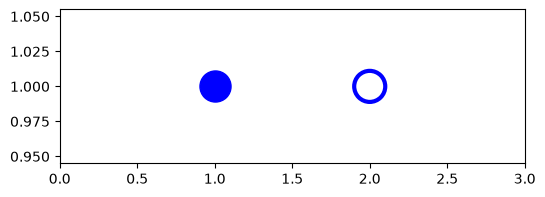

In [11]:
fig, ax = plt.subplots(figsize=(6, 2))

# filled: the inside is blue
ax.scatter([1], [1], marker='o', s=500, facecolors='blue', edgecolors='blue')

# hollow: the inside is empty, only the outline is blue
ax.scatter([2], [1], marker='o', s=500, facecolors='none', edgecolors='blue', lw=3)

ax.set_xlim(0, 3)
plt.show()

The course labs use **red X** for y=1 and **hollow blue O** for y=0, so the two groups are easy to tell apart.

## 8. Legend

A legend is the small box that says what each mark or line means. It takes **two steps**:

1. Give each `plot` or `scatter` a name with `label="..."`.
2. Call `ax.legend()` to draw the box.

If you forget step 2, there's no box. If you forget step 1, the box has nothing to show.

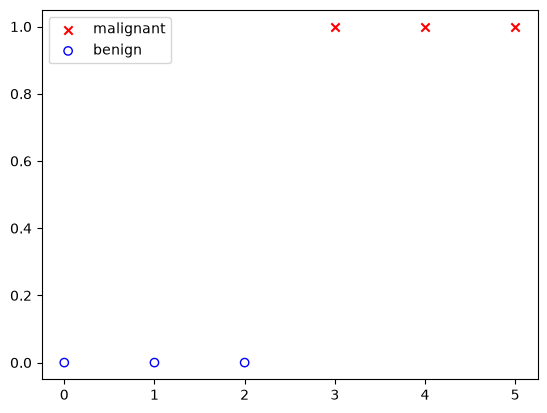

In [12]:
fig, ax = plt.subplots()

ax.scatter([3, 4, 5], [1, 1, 1], marker='x', c='red', label="malignant")
ax.scatter([0, 1, 2], [0, 0, 0], marker='o', facecolors='none', edgecolors='blue',
           label="benign")

ax.legend()   # try deleting this line and running again
plt.show()

`ax.legend(loc="upper left")` chooses where the box goes. The default, `"best"`, picks a spot that doesn't cover the data.

## 9. Axis limits

By default, matplotlib picks the ranges to fit your data. You can set them yourself:

| Code | Meaning |
|---|---|
| `ax.set_xlim(min, max)` | x-axis range |
| `ax.set_ylim(min, max)` | y-axis range |
| `ax.axis([x_min, x_max, y_min, y_max])` | both at once |

A small extra margin, like `set_ylim(-0.08, 1.1)`, stops marks at the edges from being cut in half.

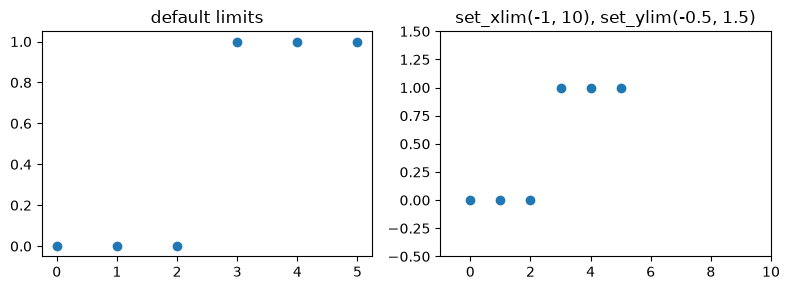

In [13]:
x = np.array([0, 1, 2, 3, 4, 5])
y = np.array([0, 0, 0, 1, 1, 1])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))

ax1.scatter(x, y)
ax1.set_title("default limits")

ax2.scatter(x, y)
ax2.set_ylim(-0.5, 1.5)
ax2.set_xlim(-1, 10)
ax2.set_title("set_xlim(-1, 10), set_ylim(-0.5, 1.5)")

plt.tight_layout()
plt.show()

## 10. Math in labels: `$x_0$`

Text between `$...$` is written as math:

| You type | You see |
|---|---|
| `'$x_0$'` | $x_0$ (small 0 below) |
| `'$x^2$'` | $x^2$ (small 2 above) |
| `'$\\alpha$'` | $\alpha$ (Greek letter alpha) |
| `'$f_{w,b}(x)$'` | $f_{w,b}(x)$ (use `{ }` when more than one character goes below) |

Use a raw string, `r'...'`, when the text has a backslash `\`, so Python leaves it alone.

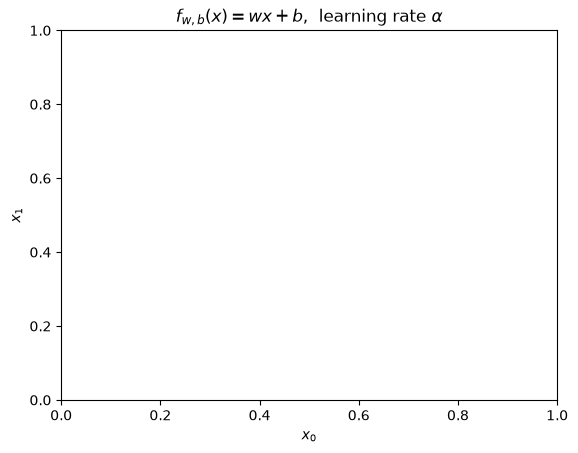

In [14]:
fig, ax = plt.subplots()
ax.set_xlabel('$x_0$')
ax.set_ylabel('$x_1$')
ax.set_title(r'$f_{w,b}(x) = wx + b$,  learning rate $\alpha$')
plt.show()

## 11. Several charts side by side: `subplots(1, 2)`

`plt.subplots(rows, columns)` makes a grid of charts. There are two common ways to name them:

```python
fig, (ax1, ax2) = plt.subplots(1, 2)   # way 1: a separate name for each chart
fig, ax = plt.subplots(1, 2)           # way 2: one list, use ax[0] and ax[1]
```

```
┌─────────────┐  ┌─────────────┐
│ ax1 / ax[0] │  │ ax2 / ax[1] │
└─────────────┘  └─────────────┘
```

Both do the same thing. Way 2 is handy when there are many charts.

To stop titles and labels from overlapping, use **one** of these:

- `plt.tight_layout()`, called before `plt.show()`.
- `constrained_layout=True`, passed to `subplots`.

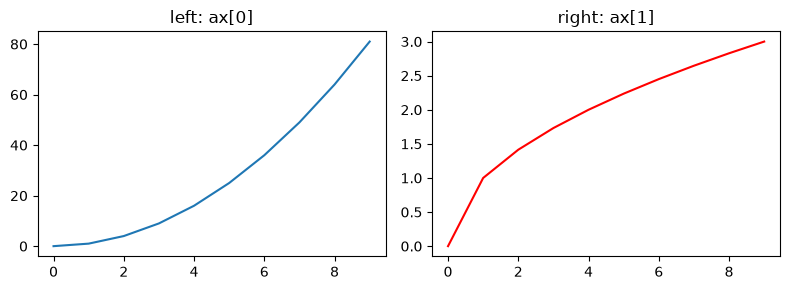

In [15]:
x = np.arange(10)

fig, ax = plt.subplots(1, 2, figsize=(8, 3))

ax[0].plot(x, x ** 2)
ax[0].set_title("left: ax[0]")

ax[1].plot(x, np.sqrt(x), c='r')
ax[1].set_title("right: ax[1]")

plt.tight_layout()
plt.show()

A 2×2 grid works the same way. Now you need **two** numbers: `ax[row, column]`.

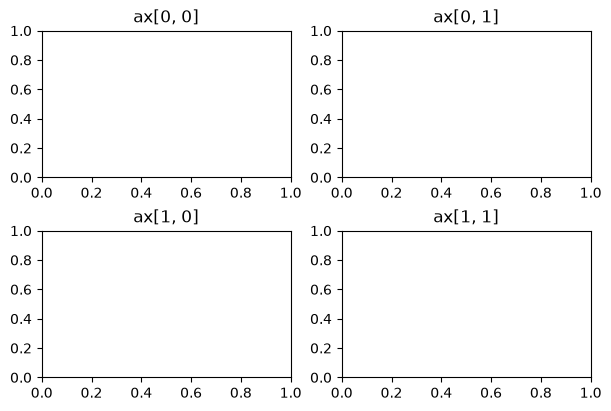

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(6, 4), constrained_layout=True)

ax[0, 0].set_title("ax[0, 0]")
ax[0, 1].set_title("ax[0, 1]")
ax[1, 0].set_title("ax[1, 0]")
ax[1, 1].set_title("ax[1, 1]")
plt.show()

## 12. Extra lines: `axhline` and `axvline`

- `ax.axhline(y=...)` draws a **horizontal** line across the whole chart.
- `ax.axvline(x=...)` draws a **vertical** line from top to bottom.

These are handy for marking a threshold, like 0.5 for classification.

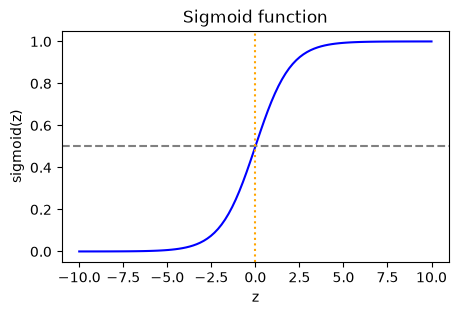

In [17]:
z = np.linspace(-10, 10, 100)
g = 1 / (1 + np.exp(-z))   # sigmoid

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(z, g, c='b')
ax.axhline(y=0.5, c='gray', linestyle='--')   # threshold 0.5
ax.axvline(x=0, c='orange', linestyle=':')    # z = 0
ax.set_xlabel('z')
ax.set_ylabel('sigmoid(z)')
ax.set_title("Sigmoid function")
plt.show()

## 13. Other common charts: bar chart and histogram

| Chart | Code | Use it for |
|---|---|---|
| Bar chart | `ax.bar(names, values)` | comparing amounts between categories |
| Histogram | `ax.hist(data, bins=20)` | seeing how values are spread out: it counts how many fall in each range ("bin") |

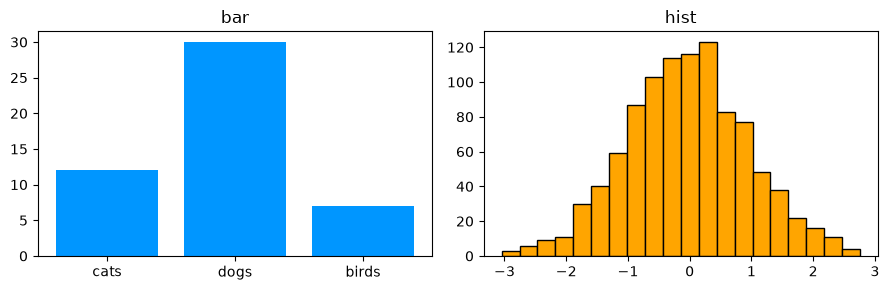

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))

# bar chart
names = ['cats', 'dogs', 'birds']
counts = [12, 30, 7]
ax[0].bar(names, counts, color='#0096ff')
ax[0].set_title("bar")

# histogram: 1000 random numbers, counted in 20 ranges
np.random.seed(0)
data = np.random.randn(1000)
ax[1].hist(data, bins=20, color='orange', edgecolor='black')
ax[1].set_title("hist")

plt.tight_layout()
plt.show()

**In ML**, a histogram of each feature is a quick way to see its range before deciding whether to scale it.

## 14. Grid lines and saving to a file

- `ax.grid(True)` adds light background lines, which make values easier to read.
- `fig.savefig("name.png")` saves the picture as an image file, in the same folder as the notebook. Call it **before** `plt.show()`.

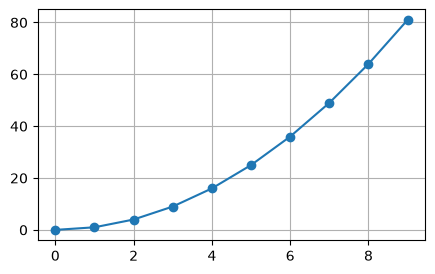

In [19]:
x = np.arange(10)

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(x, x ** 2, marker='o')
ax.grid(True)
# fig.savefig("my_chart.png", dpi=150)   # remove the # to save it (dpi = sharpness)
plt.show()

## 15. Course examples

Everything above, combined the way the labs use it.

### Cost vs. iteration, with a zoomed-in "tail"

The right-hand chart starts at iteration 100. With the large early costs gone, the y-axis zooms in, so you can see whether the cost is still going down.

`100 + np.arange(len(J_hist[100:]))` makes the x values 100, 101, 102, ..., so the x-axis shows the real iteration numbers.

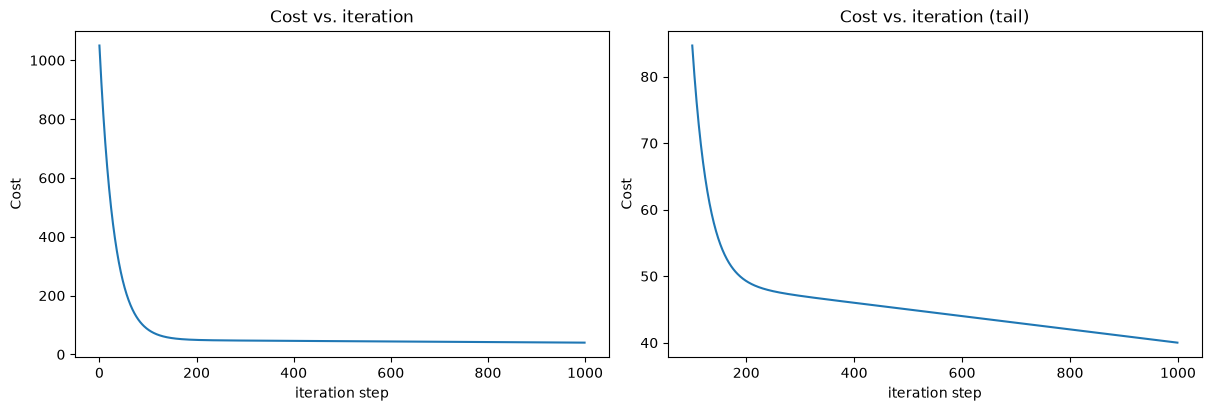

In [20]:
J_hist = 1000 * np.exp(-np.arange(1000) / 30) + 50 - np.arange(1000) * 0.01   # pretend costs

fig, (ax1, ax2) = plt.subplots(1, 2, constrained_layout=True, figsize=(12, 4))
ax1.plot(J_hist)
ax2.plot(100 + np.arange(len(J_hist[100:])), J_hist[100:])
ax1.set_title("Cost vs. iteration")
ax2.set_title("Cost vs. iteration (tail)")
ax1.set_ylabel('Cost')
ax2.set_ylabel('Cost')
ax1.set_xlabel('iteration step')
ax2.set_xlabel('iteration step')
plt.show()

### Classification data: one feature and two features

- **Left:** 1 feature. The answer y (0 or 1) is shown by **height**.
- **Right:** 2 features use up both axes, so the answer is shown by **shape**: X = 1, O = 0.

Masks (`y == 1`) split the data into the two groups. See the NumPy notebook, section 11.

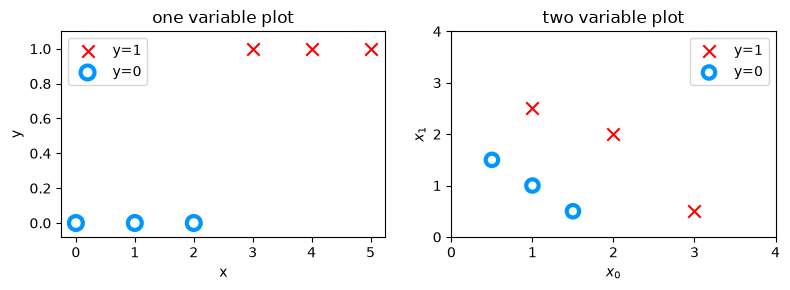

In [21]:
x_train = np.array([0., 1, 2, 3, 4, 5])
y_train = np.array([0, 0, 0, 1, 1, 1])
X_train2 = np.array([[0.5, 1.5], [1, 1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])
y_train2 = np.array([0, 0, 0, 1, 1, 1])

pos, neg = y_train == 1, y_train == 0
pos2, neg2 = y_train2 == 1, y_train2 == 0

fig, ax = plt.subplots(1, 2, figsize=(8, 3))

# left: one feature
ax[0].scatter(x_train[pos], y_train[pos], marker='x', s=80, c='red', label="y=1")
ax[0].scatter(x_train[neg], y_train[neg], marker='o', s=100, label="y=0",
              facecolors='none', edgecolors='#0096ff', lw=3)
ax[0].set_ylim(-0.08, 1.1)
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('one variable plot')
ax[0].legend()

# right: two features
ax[1].scatter(X_train2[pos2, 0], X_train2[pos2, 1], marker='x', s=80, c='red', label="y=1")
ax[1].scatter(X_train2[neg2, 0], X_train2[neg2, 1], marker='o', s=80, label="y=0",
              facecolors='none', edgecolors='#0096ff', lw=3)
ax[1].axis([0, 4, 0, 4])
ax[1].set_xlabel('$x_0$')
ax[1].set_ylabel('$x_1$')
ax[1].set_title('two variable plot')
ax[1].legend()

plt.tight_layout()
plt.show()

## 16. Cheat sheet

| Task | Code |
|---|---|
| One chart | `fig, ax = plt.subplots(figsize=(w, h))` |
| Two charts side by side | `fig, (ax1, ax2) = plt.subplots(1, 2)` or `fig, ax = plt.subplots(1, 2)` then `ax[0]`, `ax[1]` |
| Grid of charts | `fig, ax = plt.subplots(2, 2)` then `ax[row, col]` |
| Line | `ax.plot(x, y)`, or `ax.plot(y)` with automatic x |
| Dots | `ax.scatter(x, y)` |
| Bar chart / histogram | `ax.bar(names, values)`, `ax.hist(data, bins=20)` |
| Color / line type / thickness | `c='r'`, `linestyle='--'`, `lw=3` |
| Mark shape / size | `marker='x'`, `s=80` |
| Hollow circle | `marker='o', facecolors='none', edgecolors='blue'` |
| Title / labels | `ax.set_title()`, `ax.set_xlabel()`, `ax.set_ylabel()` |
| Legend | `label="..."` on each plot, then `ax.legend()` |
| Axis range | `ax.set_xlim(a, b)`, `ax.set_ylim(a, b)`, `ax.axis([x0, x1, y0, y1])` |
| Math text | `'$x_0$'`, `r'$\alpha$'` |
| Horizontal / vertical line | `ax.axhline(y=...)`, `ax.axvline(x=...)` |
| Grid lines | `ax.grid(True)` |
| Stop overlapping | `plt.tight_layout()` or `constrained_layout=True` |
| Save to a file | `fig.savefig("name.png")` (before `plt.show()`) |
| Show it | `plt.show()` |

**Practice:** draw $y = x^2$ for x from -3 to 3 as a **green dashed line**, add the data points below as **red crosses**, and give it a title, axis labels and a legend.

In [22]:
x_data = np.array([-2, -1, 0, 1, 2])
y_data = np.array([4.3, 0.8, 0.1, 1.2, 3.7])

# your code here